In [ ]:
from google.colab import drive
import zipfile
import os

# Drive'ı Colab'a bağlama
drive.mount('/content/drive')

# Zip dosyasının Drive'daki yolu
zip_path = '/content/drive/MyDrive/archive.zip'

# Verilerin çıkartılacağı geçici klasör
extract_dir = '/content/gtsrb_data'

print("Zip dosyası çıkartılıyor, bu işlem birkaç saniye sürebilir...")
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_dir)

print("Çıkarma işlemi tamamlandı! Klasör içeriği:")
print(os.listdir(extract_dir))

Mounted at /content/drive
Zip dosyası çıkartılıyor, bu işlem birkaç saniye sürebilir...
Çıkarma işlemi tamamlandı! Klasör içeriği:
['Test', 'Meta.csv', 'train', 'Meta', 'Train', 'meta', 'Train.csv', 'Test.csv', 'test']


In [ ]:
import os
import cv2
import numpy as np
from sklearn.model_selection import train_test_split

data_dir = '/content/gtsrb_data/Train'
img_size = (64, 64) # Tüm görüntüleri 64x64 piksel standart boyuta getiriyoruz

images = []
labels = []

print("Görüntüler okunuyor ve yeniden boyutlandırılıyor (Bu işlem 1-2 dakika sürebilir)...")

# GTSRB veri setinde 43 farklı trafik işareti sınıfı (0-42) bulunur
for class_id in range(43):
    class_path = os.path.join(data_dir, str(class_id))
    if not os.path.exists(class_path):
        continue

    for img_name in os.listdir(class_path):
        if img_name.endswith('.png'):
            img_path = os.path.join(class_path, img_name)
            img = cv2.imread(img_path)

            if img is not None:
                # Görüntüyü standart boyuta getirme
                img_resized = cv2.resize(img, img_size)
                images.append(img_resized)
                labels.append(class_id)

print(f"Toplam {len(images)} görüntü başarıyla yüklendi.")

# NumPy dizisine çevirme ve Normalizasyon (Piksel değerlerini 0-1 aralığına çekme)
print("Normalizasyon işlemi uygulanıyor...")
X = np.array(images, dtype='float32') / 255.0
y = np.array(labels)

print("Veriler eğitim, doğrulama ve test kümelerine ayrılıyor...")

# Önce Eğitim (%80) ve Geçici (%20) olarak ayırma
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.2, random_state=42)

# Geçici veriyi Doğrulama (%10) ve Test (%10) olarak ikiye bölme
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42)

print("\n--- Veri Kümesi Hazırlığı Tamamlandı ---")
print(f"Eğitim kümesi boyutu (X_train): {X_train.shape}")
print(f"Doğrulama kümesi boyutu (X_val): {X_val.shape}")
print(f"Test kümesi boyutu (X_test): {X_test.shape}")

Görüntüler okunuyor ve yeniden boyutlandırılıyor (Bu işlem 1-2 dakika sürebilir)...
Toplam 39209 görüntü başarıyla yüklendi.
Normalizasyon işlemi uygulanıyor...
Veriler eğitim, doğrulama ve test kümelerine ayrılıyor...

--- Veri Kümesi Hazırlığı Tamamlandı ---
Eğitim kümesi boyutu (X_train): (31367, 64, 64, 3)
Doğrulama kümesi boyutu (X_val): (3921, 64, 64, 3)
Test kümesi boyutu (X_test): (3921, 64, 64, 3)


In [ ]:
import cv2
import numpy as np

# Zaten bellekte olan (0-1 arası) verileri alıp Grayscale ve CLAHE uygulayan fonksiyon
def apply_advanced_preprocessing(X_data):
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8,8))
    processed_images = []

    # Verilerimiz 0-1 arasındaydı, OpenCV'nin işleyebilmesi için 0-255 formatına (uint8) geri çeviriyoruz
    X_uint8 = (X_data * 255).astype(np.uint8)

    for img in X_uint8:
        # 1. Renkli görüntüyü Gri Seviyeye (Grayscale) çevir
        img_gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
        # 2. CLAHE ile kontrastı dengele (karanlık/parlak alanları iyileştir)
        img_clahe = clahe.apply(img_gray)
        processed_images.append(img_clahe)

    # Sonuçları Numpy dizisine çevirip kanal sayısını 1 yapıyoruz ve tekrar normalize ediyoruz (0-1 arası)
    X_processed = np.array(processed_images, dtype='float32').reshape(-1, 64, 64, 1) / 255.0
    return X_processed

print("Eğitim kümesine Grayscale ve CLAHE uygulanıyor...")
X_train = apply_advanced_preprocessing(X_train)

print("Doğrulama kümesine Grayscale ve CLAHE uygulanıyor...")
X_val = apply_advanced_preprocessing(X_val)

print("Test kümesine Grayscale ve CLAHE uygulanıyor...")
X_test = apply_advanced_preprocessing(X_test)

print("\n--- Gelişmiş Ön İşleme Tamamlandı ---")
print(f"Eğitim kümesinin yeni boyutu: {X_train.shape}")
print(f"Doğrulama kümesinin yeni boyutu: {X_val.shape}")
print(f"Test kümesinin yeni boyutu: {X_test.shape}")

Eğitim kümesine Grayscale ve CLAHE uygulanıyor...
Doğrulama kümesine Grayscale ve CLAHE uygulanıyor...
Test kümesine Grayscale ve CLAHE uygulanıyor...

--- Gelişmiş Ön İşleme Tamamlandı ---
Eğitim kümesinin yeni boyutu: (31367, 64, 64, 1)
Doğrulama kümesinin yeni boyutu: (3921, 64, 64, 1)
Test kümesinin yeni boyutu: (3921, 64, 64, 1)


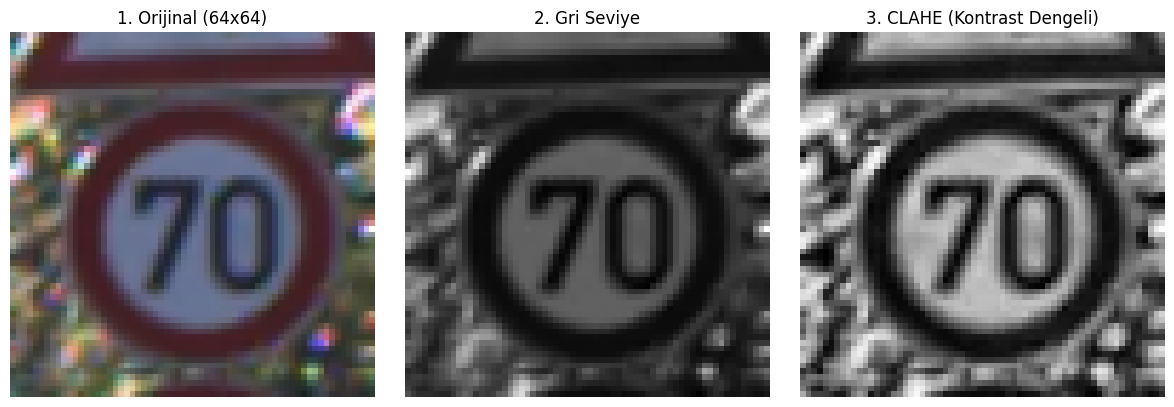

In [ ]:
import matplotlib.pyplot as plt
import cv2
import os
import random

# Klasörden rastgele bir sınıf ve resim seçiyoruz
random_class = random.choice([d for d in os.listdir(data_dir) if os.path.isdir(os.path.join(data_dir, d))])
class_path = os.path.join(data_dir, random_class)
random_img_name = random.choice([f for f in os.listdir(class_path) if f.endswith('.png')])
img_path = os.path.join(class_path, random_img_name)

# 1. Orijinal Resmi Oku ve Matplotlib için RGB'ye çevir
img_orig = cv2.imread(img_path)
img_orig_rgb = cv2.cvtColor(img_orig, cv2.COLOR_BGR2RGB)
img_resized = cv2.resize(img_orig_rgb, (64, 64))

# 2. Gri Seviyeye Çevir
img_gray = cv2.cvtColor(img_resized, cv2.COLOR_RGB2GRAY)

# 3. CLAHE Uygula
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8,8))
img_clahe = clahe.apply(img_gray)

# Görselleştirme (Yan Yana 3 Çizim)
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

axes[0].imshow(img_resized)
axes[0].set_title("1. Orijinal (64x64)")
axes[0].axis('off')

axes[1].imshow(img_gray, cmap='gray')
axes[1].set_title("2. Gri Seviye")
axes[1].axis('off')

axes[2].imshow(img_clahe, cmap='gray')
axes[2].set_title("3. CLAHE (Kontrast Dengeli)")
axes[2].axis('off')

plt.tight_layout()
plt.show()

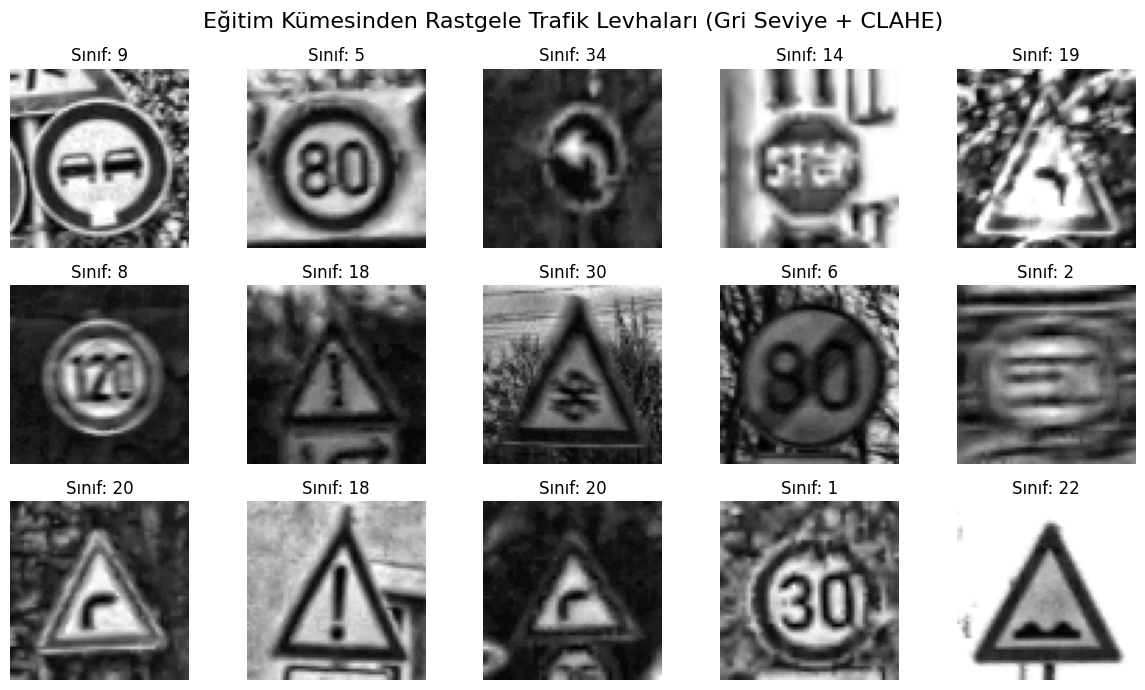

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. BÖLÜM: Eğitim Kümesinden Rastgele Örnekler Gösterme
fig, axes = plt.subplots(3, 5, figsize=(12, 7))
fig.suptitle('Eğitim Kümesinden Rastgele Trafik Levhaları (Gri Seviye + CLAHE)', fontsize=16)

for i, ax in enumerate(axes.flat):
    # Eğitim setinden rastgele bir resim seçiyoruz
    idx = np.random.randint(0, len(X_train))
    # X_train boyutumuz (64,64,1) olduğu için matplotlib'in çizebilmesi adına (64,64) yapıyoruz
    ax.imshow(X_train[idx].reshape(64, 64), cmap='gray')
    ax.set_title(f"Sınıf: {y_train[idx]}")
    ax.axis('off')

plt.tight_layout()
plt.show()


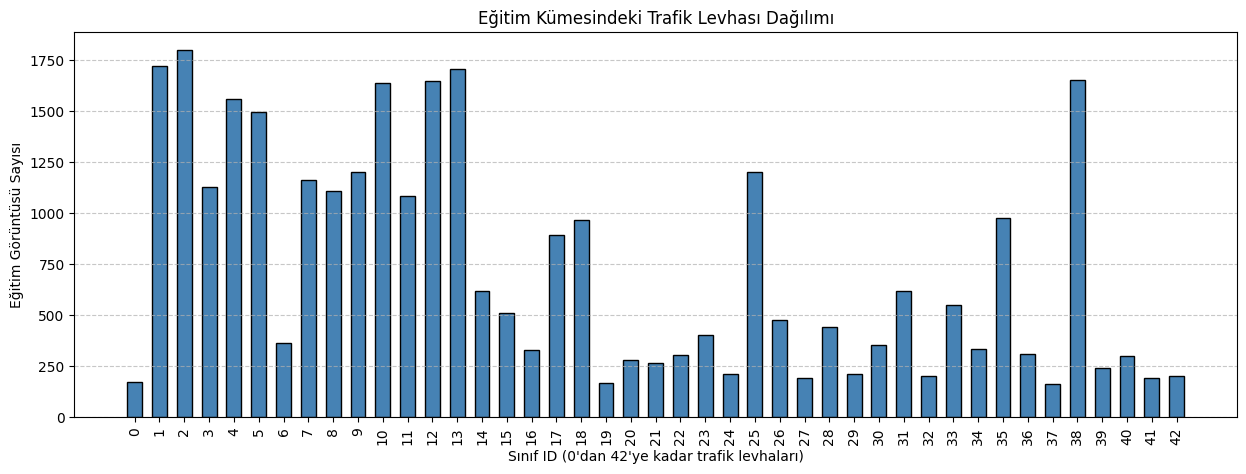

In [ ]:
# 2. BÖLÜM: Eğitim Kümesindeki Sınıf Dağılımı (Sınıf Dengesizliğini Gösterme)
# Hangi sınıftan kaç adet olduğunu sayıyoruz
classes, counts = np.unique(y_train, return_counts=True)

plt.figure(figsize=(15, 5))
plt.bar(classes, counts, width=0.6, color='steelblue', edgecolor='black')
plt.title('Eğitim Kümesindeki Trafik Levhası Dağılımı')
plt.xlabel("Sınıf ID (0'dan 42'ye kadar trafik levhaları)") # Çift tırnak ile düzeltildi
plt.ylabel('Eğitim Görüntüsü Sayısı')
plt.xticks(classes, rotation=90)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

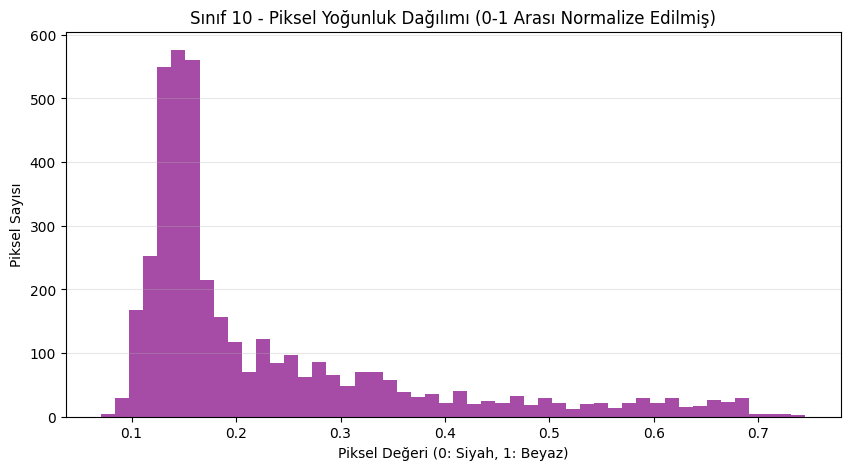

In [ ]:
import matplotlib.pyplot as plt

# Rastgele bir görüntünün piksel histogramını çıkarma
idx = np.random.randint(0, len(X_train))
sample_image = X_train[idx].flatten()

plt.figure(figsize=(10, 5))
plt.hist(sample_image, bins=50, color='purple', alpha=0.7)
plt.title(f'Sınıf {y_train[idx]} - Piksel Yoğunluk Dağılımı (0-1 Arası Normalize Edilmiş)')
plt.xlabel('Piksel Değeri (0: Siyah, 1: Beyaz)')
plt.ylabel('Piksel Sayısı')
plt.grid(axis='y', alpha=0.3)
plt.show()

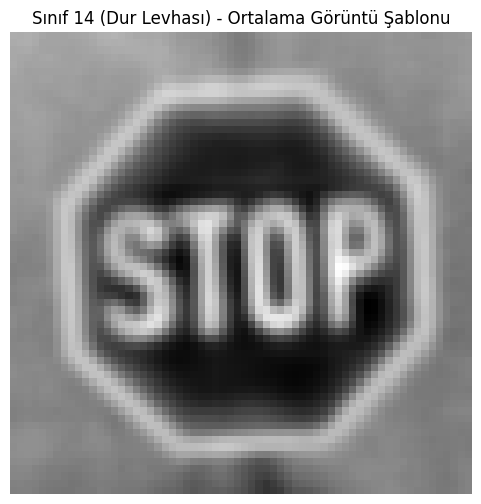

In [ ]:
# Belirli bir sınıfın (örneğin Sınıf 14 - 'Dur' levhası) ortalama görüntüsü
target_class = 14
class_images = X_train[y_train == target_class]
mean_image = np.mean(class_images, axis=0)

plt.figure(figsize=(6, 6))
plt.imshow(mean_image.reshape(64, 64), cmap='gray')
plt.title(f'Sınıf {target_class} (Dur Levhası) - Ortalama Görüntü Şablonu')
plt.axis('off')
plt.show()

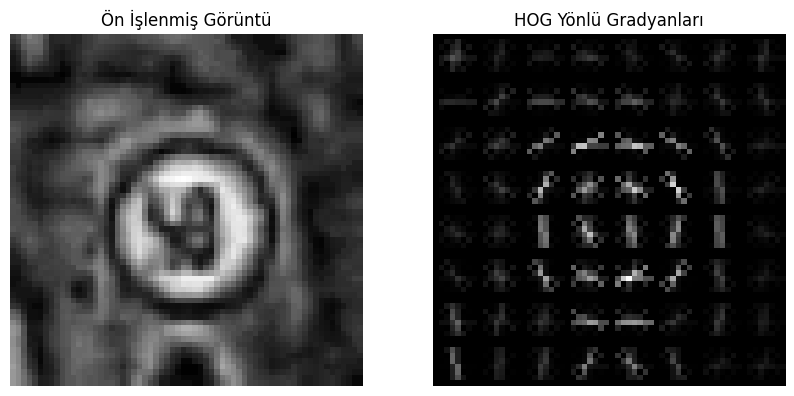

In [ ]:
from skimage.feature import hog
from skimage import exposure

# Rastgele bir resim seçip HOG görselini çıkarma
idx = np.random.randint(0, len(X_train))
image = X_train[idx].reshape(64, 64)

fd, hog_image = hog(image, orientations=9, pixels_per_cell=(8, 8),
                    cells_per_block=(2, 2), visualize=True)

# HOG görüntüsünü daha iyi görebilmek için kontrastını artırma
hog_image_rescaled = exposure.rescale_intensity(hog_image, in_range=(0, 10))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5), sharex=True, sharey=True)

ax1.axis('off')
ax1.imshow(image, cmap='gray')
ax1.set_title('Ön İşlenmiş Görüntü')

ax2.axis('off')
ax2.imshow(hog_image_rescaled, cmap='gray')
ax2.set_title('HOG Yönlü Gradyanları')
plt.show()

In [ ]:
from skimage.feature import hog
import numpy as np
import time

def extract_hog_features(images):
    hog_features = []
    for img in images:
        # Resimlerimiz (64, 64, 1) formatındaydı, HOG algoritmasının daha rahat işlemesi için
        # sondaki '1' kanalını atıp (64, 64) formatına (2 boyutluya) sıkıştırıyoruz.
        img_squeezed = np.squeeze(img)

        # HOG özniteliklerini hesaplıyoruz
        features = hog(img_squeezed,
                       orientations=9,
                       pixels_per_cell=(8, 8),
                       cells_per_block=(2, 2),
                       visualize=False)
        hog_features.append(features)
    return np.array(hog_features)

print("Eğitim kümesi için HOG öznitelikleri çıkarılıyor (Lütfen bekleyin)...")
start_time = time.time()
X_train_features = extract_hog_features(X_train)
print(f"Eğitim kümesi tamamlandı! (Süre: {time.time() - start_time:.2f} saniye)")

print("Doğrulama kümesi için HOG öznitelikleri çıkarılıyor...")
X_val_features = extract_hog_features(X_val)

print("Test kümesi için HOG öznitelikleri çıkarılıyor...")
X_test_features = extract_hog_features(X_test)

print("\n--- Öznitelik Çıkarımı Tamamlandı ---")
print(f"Eğitim kümesinin orijinal boyutu: {X_train.shape}")
print(f"Eğitim kümesinin HOG öznitelik boyutu: {X_train_features.shape}")

Eğitim kümesi için HOG öznitelikleri çıkarılıyor (Lütfen bekleyin)...
Eğitim kümesi tamamlandı! (Süre: 39.36 saniye)
Doğrulama kümesi için HOG öznitelikleri çıkarılıyor...
Test kümesi için HOG öznitelikleri çıkarılıyor...

--- Öznitelik Çıkarımı Tamamlandı ---
Eğitim kümesinin orijinal boyutu: (31367, 64, 64, 1)
Eğitim kümesinin HOG öznitelik boyutu: (31367, 1764)


In [ ]:
from skimage.feature import local_binary_pattern
import numpy as np
import time

# LBP (Yerel İkili Örüntüler) parametreleri
radius = 3
n_points = 8 * radius

def extract_lbp_features(images):
    lbp_features = []
    for img in images:
        img_squeezed = np.squeeze(img)
        # LBP algoritmasını uygulama
        lbp = local_binary_pattern(img_squeezed, n_points, radius, method='uniform')

        # LBP sonuçlarını histograma (sayısal vektöre) çevirme
        n_bins = int(lbp.max() + 1)
        hist, _ = np.histogram(lbp.ravel(), bins=n_bins, range=(0, n_bins))

        # Histogramı normalize etme (0 ile 1 arasına çekme)
        hist = hist.astype("float")
        hist /= (hist.sum() + 1e-7)

        lbp_features.append(hist)
    return np.array(lbp_features)

print("LBP öznitelikleri çıkarılıyor (Lütfen bekleyin)...")
start_time = time.time()

# LBP özniteliklerini çıkarma
X_train_lbp = extract_lbp_features(X_train)
X_val_lbp = extract_lbp_features(X_val)
X_test_lbp = extract_lbp_features(X_test)

print(f"LBP işlemi tamamlandı! (Süre: {time.time() - start_time:.2f} saniye)")

print("\nHOG ve LBP öznitelikleri birleştiriliyor (Feature Fusion/Concatenation)...")
# Numpy hstack ile önceki adımdaki HOG vektörlerinin yanına yeni LBP vektörlerini ekliyoruz
X_train_combined = np.hstack((X_train_features, X_train_lbp))
X_val_combined = np.hstack((X_val_features, X_val_lbp))
X_test_combined = np.hstack((X_test_features, X_test_lbp))

print("\n--- Çoklu Öznitelik Çıkarımı Tamamlandı ---")
print(f"Sadece HOG boyutu: {X_train_features.shape}")
print(f"Sadece LBP boyutu: {X_train_lbp.shape}")
print(f"Birleştirilmiş (HOG + LBP) Model Girdisi Boyutu: {X_train_combined.shape}")

LBP öznitelikleri çıkarılıyor (Lütfen bekleyin)...


/usr/local/lib/python3.13/dist-packages/skimage/feature/texture.py:385: UserWarning: Applying `local_binary_pattern` to floating-point images may give unexpected results when small numerical differences between adjacent pixels are present. It is recommended to use this function with images of integer dtype.
  warnings.warn(


LBP işlemi tamamlandı! (Süre: 87.64 saniye)

HOG ve LBP öznitelikleri birleştiriliyor (Feature Fusion/Concatenation)...

--- Çoklu Öznitelik Çıkarımı Tamamlandı ---
Sadece HOG boyutu: (31367, 1764)
Sadece LBP boyutu: (31367, 26)
Birleştirilmiş (HOG + LBP) Model Girdisi Boyutu: (31367, 1790)


In [ ]:
import cv2
import numpy as np
import time

def extract_edge_features(images):
    edge_features = []
    for img in images:
        # 1. Görüntü formatını Canny'nin anlayacağı 0-255 (uint8) aralığına geri çeviriyoruz
        img_uint8 = (np.squeeze(img) * 255).astype(np.uint8)

        # 2. Canny algoritması ile kenarları buluyoruz
        edges = cv2.Canny(img_uint8, threshold1=100, threshold2=200)

        # 3. Görüntüyü 4 eşit parçaya (çeyreğe) bölüyoruz
        h, w = edges.shape
        q1 = edges[0:h//2, 0:w//2]   # Sol Üst
        q2 = edges[0:h//2, w//2:w]   # Sağ Üst
        q3 = edges[h//2:h, 0:w//2]   # Sol Alt
        q4 = edges[h//2:h, w//2:w]   # Sağ Alt

        # 4. Her bir çeyrekteki kenar piksellerinin (beyazların) yoğunluğunu hesaplıyoruz
        densities = [
            np.sum(q1 == 255) / q1.size,
            np.sum(q2 == 255) / q2.size,
            np.sum(q3 == 255) / q3.size,
            np.sum(q4 == 255) / q4.size
        ]
        edge_features.append(densities)

    return np.array(edge_features)

print("Kenar tabanlı öznitelikler çıkarılıyor...")
start_time = time.time()

X_train_edges = extract_edge_features(X_train)
X_val_edges = extract_edge_features(X_val)
X_test_edges = extract_edge_features(X_test)

print(f"Kenar çıkarma işlemi tamamlandı! (Süre: {time.time() - start_time:.2f} saniye)")

print("\nTüm Öznitelikler (HOG + LBP + Kenar) birleştiriliyor...")
# HOG ve LBP'yi birleştirdiğimiz 'X_train_combined' verisinin sonuna 4 boyutlu Kenar vektörünü de ekliyoruz
X_train_final = np.hstack((X_train_combined, X_train_edges))
X_val_final = np.hstack((X_val_combined, X_val_edges))
X_test_final = np.hstack((X_test_combined, X_test_edges))

print("\n--- Zenginleştirilmiş Öznitelik Çıkarımı Tamamlandı ---")
print(f"Nihai Model Girdisi Boyutu: {X_train_final.shape}")

Kenar tabanlı öznitelikler çıkarılıyor...
Kenar çıkarma işlemi tamamlandı! (Süre: 5.26 saniye)

Tüm Öznitelikler (HOG + LBP + Kenar) birleştiriliyor...

--- Zenginleştirilmiş Öznitelik Çıkarımı Tamamlandı ---
Nihai Model Girdisi Boyutu: (31367, 1794)


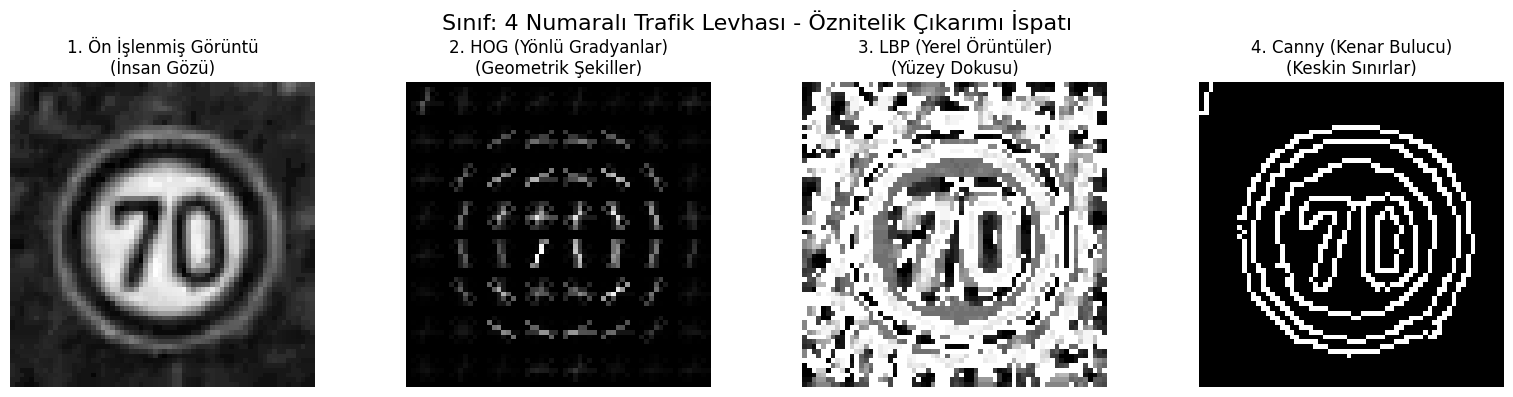

In [ ]:
import matplotlib.pyplot as plt
from skimage.feature import hog, local_binary_pattern
import cv2
import numpy as np

# 1. Eğitim setinden rastgele bir levha seçiyoruz
idx = np.random.randint(0, len(X_train))
# Resmimizi (64, 64) boyutuna getiriyoruz (sondaki 1'i atıyoruz)
sample_img = np.squeeze(X_train[idx])
label = y_train[idx]

# 2. HOG Görselini Çıkarma (Şekil Algısı)
_, hog_image = hog(sample_img, orientations=9, pixels_per_cell=(8, 8),
                   cells_per_block=(2, 2), visualize=True)

# 3. LBP Görselini Çıkarma (Doku Algısı)
radius = 3
n_points = 8 * radius
lbp_image = local_binary_pattern(sample_img, n_points, radius, method='uniform')

# 4. Canny Görselini Çıkarma (Kenar Algısı)
# Canny 0-255 formatı istediği için dönüştürüyoruz
img_uint8 = (sample_img * 255).astype(np.uint8)
canny_image = cv2.Canny(img_uint8, threshold1=100, threshold2=200)

# 5. İspat Çizimlerini Yan Yana Gösterme
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
fig.suptitle(f"Sınıf: {label} Numaralı Trafik Levhası - Öznitelik Çıkarımı İspatı", fontsize=16)

# Orijinal (Ön İşlenmiş) Hal
axes[0].imshow(sample_img, cmap='gray')
axes[0].set_title("1. Ön İşlenmiş Görüntü\n(İnsan Gözü)")
axes[0].axis('off')

# HOG Hal
axes[1].imshow(hog_image, cmap='gray')
axes[1].set_title("2. HOG (Yönlü Gradyanlar)\n(Geometrik Şekiller)")
axes[1].axis('off')

# LBP Hal
axes[2].imshow(lbp_image, cmap='gray')
axes[2].set_title("3. LBP (Yerel Örüntüler)\n(Yüzey Dokusu)")
axes[2].axis('off')

# Canny Hal
axes[3].imshow(canny_image, cmap='gray')
axes[3].set_title("4. Canny (Kenar Bulucu)\n(Keskin Sınırlar)")
axes[3].axis('off')

plt.tight_layout()
plt.show()

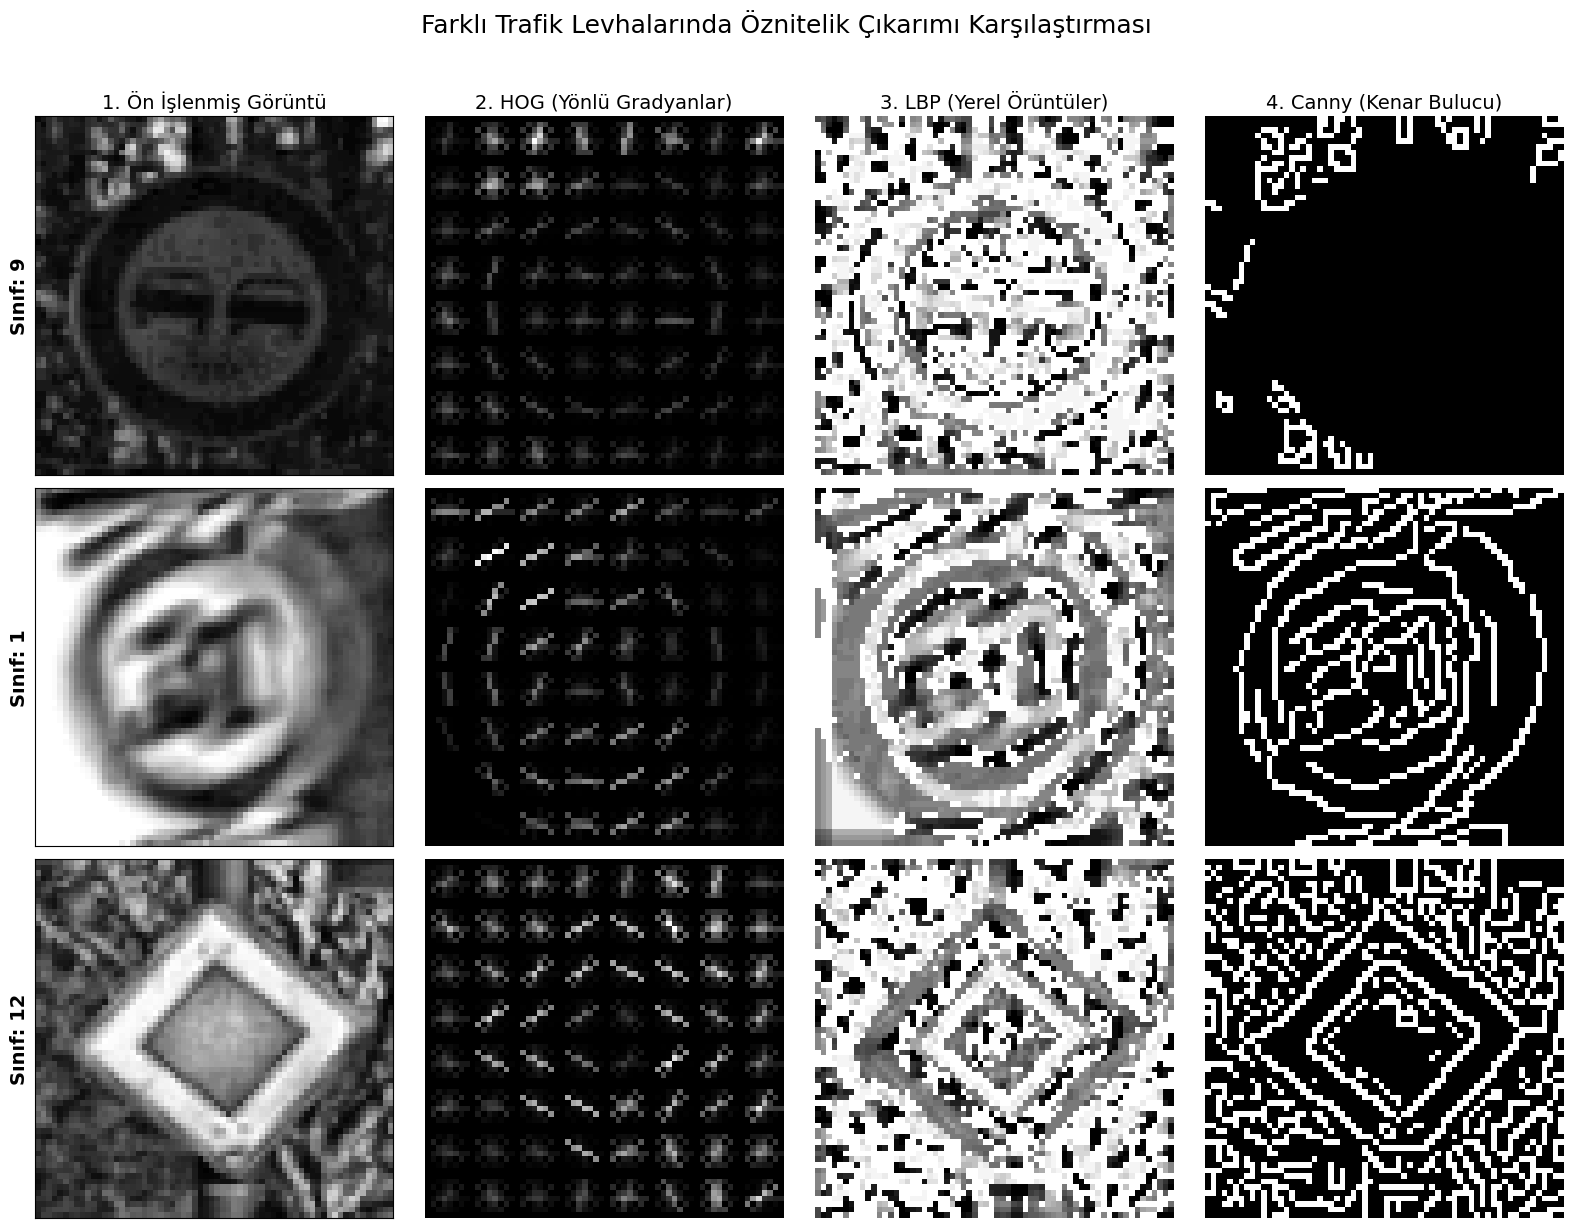

In [ ]:
import matplotlib.pyplot as plt
from skimage.feature import hog, local_binary_pattern
import cv2
import numpy as np

# 3 farklı rastgele resim seçiyoruz
num_samples = 3
random_indices = np.random.choice(len(X_train), num_samples, replace=False)

fig, axes = plt.subplots(num_samples, 4, figsize=(16, 4 * num_samples))
fig.suptitle("Farklı Trafik Levhalarında Öznitelik Çıkarımı Karşılaştırması", fontsize=18, y=1.02)

for row, idx in enumerate(random_indices):
    sample_img = np.squeeze(X_train[idx])
    label = y_train[idx]

    # 1. HOG
    _, hog_image = hog(sample_img, orientations=9, pixels_per_cell=(8, 8), cells_per_block=(2, 2), visualize=True)
    # 2. LBP
    radius = 3
    n_points = 8 * radius
    lbp_image = local_binary_pattern(sample_img, n_points, radius, method='uniform')
    # 3. Canny
    img_uint8 = (sample_img * 255).astype(np.uint8)
    canny_image = cv2.Canny(img_uint8, threshold1=100, threshold2=200)

    # --- ÇİZİMLER ---
    # Orijinal
    axes[row, 0].imshow(sample_img, cmap='gray')
    axes[row, 0].set_ylabel(f"Sınıf: {label}", fontsize=14, fontweight='bold')
    axes[row, 0].set_xticks([])
    axes[row, 0].set_yticks([])
    if row == 0: axes[row, 0].set_title("1. Ön İşlenmiş Görüntü", fontsize=14)

    # HOG
    axes[row, 1].imshow(hog_image, cmap='gray')
    axes[row, 1].axis('off')
    if row == 0: axes[row, 1].set_title("2. HOG (Yönlü Gradyanlar)", fontsize=14)

    # LBP
    axes[row, 2].imshow(lbp_image, cmap='gray')
    axes[row, 2].axis('off')
    if row == 0: axes[row, 2].set_title("3. LBP (Yerel Örüntüler)", fontsize=14)

    # Canny
    axes[row, 3].imshow(canny_image, cmap='gray')
    axes[row, 3].axis('off')
    if row == 0: axes[row, 3].set_title("4. Canny (Kenar Bulucu)", fontsize=14)

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import time

print("1. Özellikler standartlaştırılıyor (StandardScaler)...")
scaler = StandardScaler()

# DİKKAT: Veri sızıntısını (Data Leakage) önlemek için 'fit' işlemini SADECE eğitim setine yapıyoruz!
X_train_scaled = scaler.fit_transform(X_train_final)
X_val_scaled = scaler.transform(X_val_final)
X_test_scaled = scaler.transform(X_test_final)

print("2. PCA ile Boyut İndirgeme uygulanıyor...")
start_time = time.time()

# n_components=0.95 demek: "Verideki toplam bilginin (varyansın) %95'ini koruyacak kadar bileşen seç, gerisini (gürültüyü) at."
pca = PCA(n_components=0.95, random_state=42)

X_train_pca = pca.fit_transform(X_train_scaled)
X_val_pca = pca.transform(X_val_scaled)
X_test_pca = pca.transform(X_test_scaled)

print(f"PCA işlemi tamamlandı! (Süre: {time.time() - start_time:.2f} saniye)")

print("\n--- Model Öncesi Son Hazırlık (PCA) Tamamlandı ---")
print(f"Orijinal birleştirilmiş özellik (sütun) sayısı: {X_train_final.shape[1]}")
print(f"PCA sonrası süzülmüş özellik (sütun) sayısı: {X_train_pca.shape[1]}")

1. Özellikler standartlaştırılıyor (StandardScaler)...
2. PCA ile Boyut İndirgeme uygulanıyor...
PCA işlemi tamamlandı! (Süre: 31.61 saniye)

--- Model Öncesi Son Hazırlık (PCA) Tamamlandı ---
Orijinal birleştirilmiş özellik (sütun) sayısı: 1794
PCA sonrası süzülmüş özellik (sütun) sayısı: 491


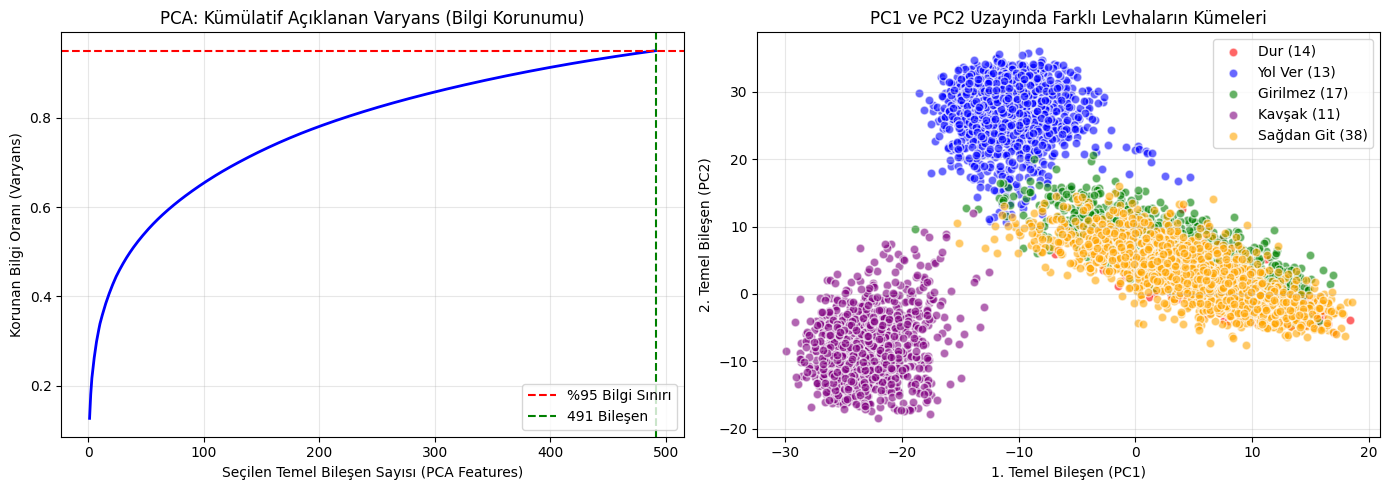

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. GRAFİK: Kümülatif Açıklanan Varyans (Scree Plot)
# pca nesnemiz %95'i açıklayan 491 bileşeni tutuyor. Bunların kümülatif toplamını alıyoruz.
cumulative_variance = np.cumsum(pca.explained_variance_ratio_)
axes[0].plot(range(1, len(cumulative_variance) + 1), cumulative_variance, color='b', linewidth=2)
axes[0].axhline(y=0.95, color='r', linestyle='--', label='%95 Bilgi Sınırı')
axes[0].axvline(x=pca.n_components_, color='g', linestyle='--', label=f'{pca.n_components_} Bileşen')
axes[0].set_title('PCA: Kümülatif Açıklanan Varyans (Bilgi Korunumu)', fontsize=12)
axes[0].set_xlabel('Seçilen Temel Bileşen Sayısı (PCA Features)')
axes[0].set_ylabel('Korunan Bilgi Oranı (Varyans)')
axes[0].legend(loc='lower right')
axes[0].grid(True, alpha=0.3)

# 2. GRAFİK: İlk İki Temel Bileşenin Dağılımı (Sadece seçili 5 sınıf)
# Karmaşayı önlemek için şekil olarak birbirinden farklı 5 levha seçiyoruz:
# 14 (Dur - Sekizgen), 13 (Yol Ver - Ters Üçgen), 17 (Girilmez - Yuvarlak), 11 (Kavşak - Üçgen), 38 (Sağdan Git - Ok)
selected_classes = [14, 13, 17, 11, 38]
colors = ['red', 'blue', 'green', 'purple', 'orange']
labels = ['Dur (14)', 'Yol Ver (13)', 'Girilmez (17)', 'Kavşak (11)', 'Sağdan Git (38)']

for cls, color, label in zip(selected_classes, colors, labels):
    indices = y_train == cls
    # Sadece o sınıfa ait 0. (PC1) ve 1. (PC2) sütunları çizdiriyoruz
    axes[1].scatter(X_train_pca[indices, 0], X_train_pca[indices, 1],
                c=color, label=label, alpha=0.6, edgecolors='w', s=40)

axes[1].set_title('PC1 ve PC2 Uzayında Farklı Levhaların Kümeleri', fontsize=12)
axes[1].set_xlabel('1. Temel Bileşen (PC1)')
axes[1].set_ylabel('2. Temel Bileşen (PC2)')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
import time

print("Random Forest modeli eğitiliyor (Bu işlem verinin büyüklüğüne göre 1-3 dakika sürebilir)...")
start_time = time.time()

# n_estimators=200: 200 adet karar ağacı oluşturulacak
# n_jobs=-1: Eğitimi hızlandırmak için bilgisayarın/Colab'ın tüm işlemci çekirdeklerini kullan
rf_model = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
rf_model.fit(X_train_pca, y_train)

print(f"Model eğitimi tamamlandı! (Süre: {time.time() - start_time:.2f} saniye)")

print("\nDoğrulama (Validation) kümesi üzerinde tahmin yapılıyor ve performans ölçülüyor...")
y_val_pred = rf_model.predict(X_val_pca)

# Başarı oranını hesaplama
val_accuracy = accuracy_score(y_val, y_val_pred)
print(f"\n--- DOĞRULAMA KÜMESİ DOĞRULUĞU (ACCURACY): %{val_accuracy * 100:.2f} ---")

# Detaylı Sınıflandırma Raporu (Hangi levhayı ne kadar iyi tanıyor?)
print("\nDetaylı Sınıflandırma Raporu (İlk 10 Sınıf İçin):")
# 43 sınıfın tamamı çok uzun süreceği için raporu sadece ilk 10 sınıfı gösterecek şekilde kırpıyoruz
report = classification_report(y_val, y_val_pred, digits=4, output_dict=True)

# Çıktıyı okunabilir formatta yazdırma
print(f"{'Sınıf':<10} | {'Hassasiyet (Precision)':<25} | {'Duyarlılık (Recall)':<20} | {'F1-Skoru'}")
print("-" * 75)
for i in range(10):
    cls_data = report[str(i)]
    print(f"Sınıf {i:<4} | {cls_data['precision']:<25.4f} | {cls_data['recall']:<20.4f} | {cls_data['f1-score']:.4f}")

Random Forest modeli eğitiliyor (Bu işlem verinin büyüklüğüne göre 1-3 dakika sürebilir)...
Model eğitimi tamamlandı! (Süre: 205.01 saniye)

Doğrulama (Validation) kümesi üzerinde tahmin yapılıyor ve performans ölçülüyor...

--- DOĞRULAMA KÜMESİ DOĞRULUĞU (ACCURACY): %87.27 ---

Detaylı Sınıflandırma Raporu (İlk 10 Sınıf İçin):
Sınıf      | Hassasiyet (Precision)    | Duyarlılık (Recall)  | F1-Skoru
---------------------------------------------------------------------------
Sınıf 0    | 1.0000                    | 0.2667               | 0.4211
Sınıf 1    | 0.8724                    | 0.8154               | 0.8429
Sınıf 2    | 0.7370                    | 0.9221               | 0.8192
Sınıf 3    | 0.9362                    | 0.6718               | 0.7822
Sınıf 4    | 0.8750                    | 0.9515               | 0.9116
Sınıf 5    | 0.7880                    | 0.7796               | 0.7838
Sınıf 6    | 1.0000                    | 0.9412               | 0.9697
Sınıf 7    | 0.8963     

Random Forest modeli, daha önce hiç görmediği TEST KÜMESİ üzerinde değerlendiriliyor...
Test tahmini tamamlandı! (Süre: 1.11 saniye)

--- RANDOM FOREST FİNAL TEST KÜMESİ DOĞRULUĞU: %87.22 ---


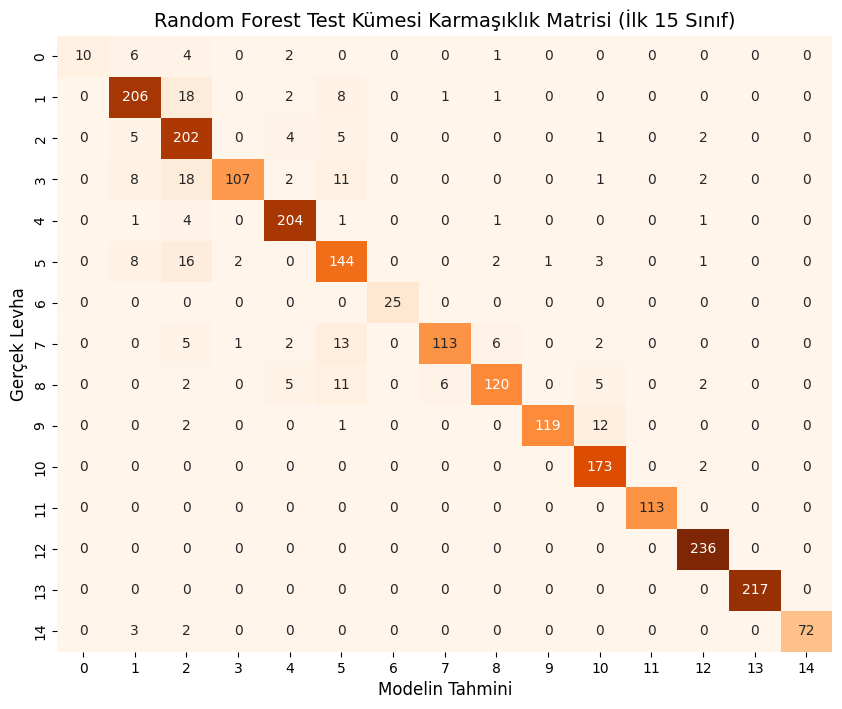

In [ ]:
print("Random Forest modeli, daha önce hiç görmediği TEST KÜMESİ üzerinde değerlendiriliyor...")
start_time = time.time()

# Test verisi üzerinde tahmin yapıyoruz
y_test_pred_rf = rf_model.predict(X_test_pca)
test_accuracy_rf = accuracy_score(y_test, y_test_pred_rf)

print(f"Test tahmini tamamlandı! (Süre: {time.time() - start_time:.2f} saniye)")
print(f"\n--- RANDOM FOREST FİNAL TEST KÜMESİ DOĞRULUĞU: %{test_accuracy_rf * 100:.2f} ---")

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# İlk 15 sınıf için Random Forest karmaşıklık matrisi
cm_rf = confusion_matrix(y_test, y_test_pred_rf)
cm_subset_rf = cm_rf[:15, :15]

plt.figure(figsize=(10, 8))
# SVM'den ayırt edilmesi kolay olsun diye turuncu renk paleti (Oranges) kullanıyoruz
sns.heatmap(cm_subset_rf, annot=True, fmt='d', cmap='Oranges', cbar=False)
plt.title('Random Forest Test Kümesi Karmaşıklık Matrisi (İlk 15 Sınıf)', fontsize=14)
plt.xlabel('Modelin Tahmini', fontsize=12)
plt.ylabel('Gerçek Levha', fontsize=12)
plt.show()

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
import time

print("GELİŞTİRİLMİŞ RANDOM FOREST EĞİTİLİYOR...")
print("- PCA iptal edildi, tüm özellikler (Scaled) kullanılıyor.")
print("- Azınlık sınıfları için 'balanced' ağırlıklandırma devrede.")
start_time = time.time()

# 1. ÖNERİ: class_weight='balanced' eklendi
# 2. ÖNERİ: X_train_pca YERİNE X_train_scaled kullanıyoruz
rf_model_optimized = RandomForestClassifier(n_estimators=200,
                                            class_weight='balanced',
                                            random_state=42,
                                            n_jobs=-1)

# Eğitimi başlatıyoruz (PCA'siz veri daha büyük olduğu için 3-5 dakika sürebilir)
rf_model_optimized.fit(X_train_scaled, y_train)
print(f"Eğitim tamamlandı! (Süre: {time.time() - start_time:.2f} saniye)")

print("\nGeliştirilmiş model Doğrulama (Validation) kümesinde test ediliyor...")
y_val_pred_opt = rf_model_optimized.predict(X_val_scaled)
val_accuracy_opt = accuracy_score(y_val, y_val_pred_opt)
print(f"--- YENİ DOĞRULAMA KÜMESİ DOĞRULUĞU: %{val_accuracy_opt * 100:.2f} ---")

print("\nGeliştirilmiş model TEST KÜMESİ üzerinde değerlendiriliyor...")
y_test_pred_opt = rf_model_optimized.predict(X_test_scaled)
test_accuracy_opt = accuracy_score(y_test, y_test_pred_opt)
print(f"🏆 YENİ FİNAL TEST KÜMESİ DOĞRULUĞU: %{test_accuracy_opt * 100:.2f} 🏆")

GELİŞTİRİLMİŞ RANDOM FOREST EĞİTİLİYOR...
- PCA iptal edildi, tüm özellikler (Scaled) kullanılıyor.
- Azınlık sınıfları için 'balanced' ağırlıklandırma devrede.
Eğitim tamamlandı! (Süre: 377.25 saniye)

Geliştirilmiş model Doğrulama (Validation) kümesinde test ediliyor...
--- YENİ DOĞRULAMA KÜMESİ DOĞRULUĞU: %95.69 ---

Geliştirilmiş model TEST KÜMESİ üzerinde değerlendiriliyor...
🏆 YENİ FİNAL TEST KÜMESİ DOĞRULUĞU: %95.92 🏆


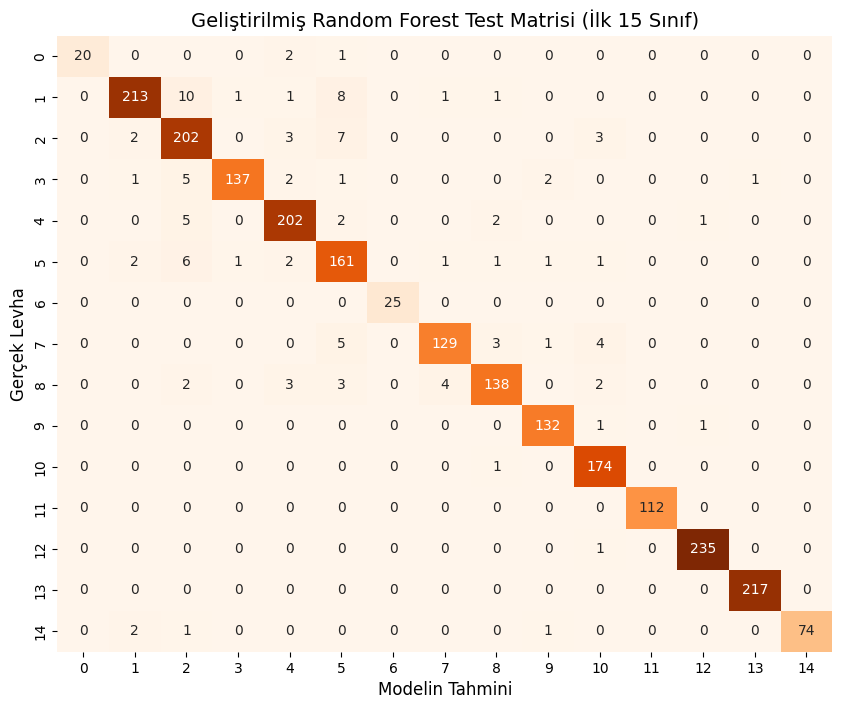

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Geliştirilmiş Random Forest için karmaşıklık matrisinin hesaplanması
cm_rf_opt = confusion_matrix(y_test, y_test_pred_opt)

# Sadece ilk 15 sınıfı alıyoruz
cm_subset_rf_opt = cm_rf_opt[:15, :15]

plt.figure(figsize=(10, 8))
# Eski RF matrisiyle aynı renkte (Oranges) çizdiriyoruz ki karşılaştırması kolay olsun
sns.heatmap(cm_subset_rf_opt, annot=True, fmt='d', cmap='Oranges', cbar=False)
plt.title('Geliştirilmiş Random Forest Test Matrisi (İlk 15 Sınıf)', fontsize=14)
plt.xlabel('Modelin Tahmini', fontsize=12)
plt.ylabel('Gerçek Levha', fontsize=12)
plt.show()

In [ ]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
import time

print("SVM modeli eğitiliyor...")
print("(NOT: SVM'in karmaşık hiperdüzlem matematiği nedeniyle bu işlem Random Forest'tan daha uzun, tahmini 5-15 dakika sürebilir. Lütfen bekleyin.)")
start_time = time.time()

# kernel='rbf': Görüntü gibi karmaşık verilerde doğrusal olmayan sınırları çizebilen en güçlü çekirdek türü
svm_model = SVC(kernel='rbf', C=1.0, random_state=42)
svm_model.fit(X_train_pca, y_train)

print(f"SVM eğitimi tamamlandı! (Süre: {time.time() - start_time:.2f} saniye)")

print("\nDoğrulama (Validation) kümesi üzerinde SVM tahmini yapılıyor...")
y_val_pred_svm = svm_model.predict(X_val_pca)

# Başarı oranını hesaplama
svm_accuracy = accuracy_score(y_val, y_val_pred_svm)
print(f"\n--- SVM DOĞRULAMA KÜMESİ DOĞRULUĞU (ACCURACY): %{svm_accuracy * 100:.2f} ---")

SVM modeli eğitiliyor...
(NOT: SVM'in karmaşık hiperdüzlem matematiği nedeniyle bu işlem Random Forest'tan daha uzun, tahmini 5-15 dakika sürebilir. Lütfen bekleyin.)
SVM eğitimi tamamlandı! (Süre: 86.28 saniye)

Doğrulama (Validation) kümesi üzerinde SVM tahmini yapılıyor...

--- SVM DOĞRULAMA KÜMESİ DOĞRULUĞU (ACCURACY): %98.62 ---


Şampiyon model (SVM), daha önce hiç görmediği TEST KÜMESİ üzerinde değerlendiriliyor...
Test tahmini tamamlandı! (Süre: 38.81 saniye)

🏆 FİNAL TEST KÜMESİ DOĞRULUĞU (ACCURACY): %98.72 🏆



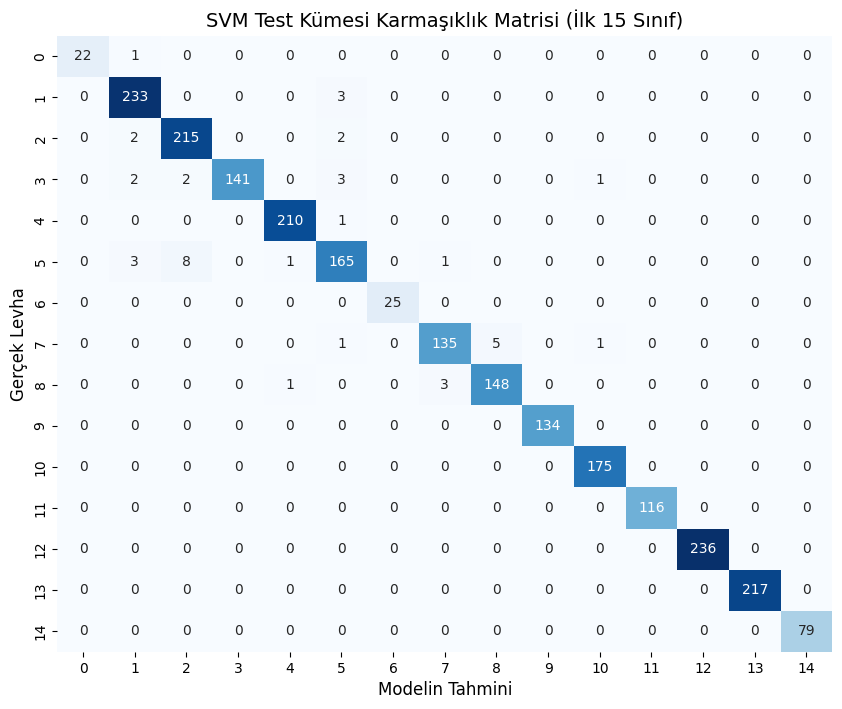

In [ ]:
print("Şampiyon model (SVM), daha önce hiç görmediği TEST KÜMESİ üzerinde değerlendiriliyor...")
start_time = time.time()

y_test_pred_svm = svm_model.predict(X_test_pca)
test_accuracy = accuracy_score(y_test, y_test_pred_svm)

print(f"Test tahmini tamamlandı! (Süre: {time.time() - start_time:.2f} saniye)")
print(f"\n=======================================================")
print(f"🏆 FİNAL TEST KÜMESİ DOĞRULUĞU (ACCURACY): %{test_accuracy * 100:.2f} 🏆")
print(f"=======================================================\n")

# Hangi levhalarda hata yaptığını detaylı görebilmek için karmaşıklık matrisini (Confusion Matrix) çizdirelim
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Sadece ilk 15 sınıfı çizdirelim ki grafik çok karmaşık olmasın
cm = confusion_matrix(y_test, y_test_pred_svm)
cm_subset = cm[:15, :15]

plt.figure(figsize=(10, 8))
sns.heatmap(cm_subset, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title('SVM Test Kümesi Karmaşıklık Matrisi (İlk 15 Sınıf)', fontsize=14)
plt.xlabel('Modelin Tahmini', fontsize=12)
plt.ylabel('Gerçek Levha', fontsize=12)
plt.show()

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

# Şampiyon modelimizin test tahminleri üzerinden genel metrikleri hesaplıyoruz
# Ortalama olarak 'weighted' (veri sayısına göre ağırlıklandırılmış) kullanmak dengesiz veri setlerinde en doğrusudur.
accuracy = accuracy_score(y_test, y_test_pred_svm)
precision = precision_score(y_test, y_test_pred_svm, average='weighted')
recall = recall_score(y_test, y_test_pred_svm, average='weighted')
f1 = f1_score(y_test, y_test_pred_svm, average='weighted')

print("===================================================================")
print(" 4. PERFORMANS DEĞERLENDİRMESİ (ŞAMPİYON MODEL: SVM - TEST KÜMESİ)")
print("===================================================================")
print(f"Doğruluk (Accuracy)   : % {accuracy * 100:.2f}")
print(f"Kesinlik (Precision)  : % {precision * 100:.2f}")
print(f"Duyarlılık (Recall)   : % {recall * 100:.2f}")
print(f"F1-Skoru              : % {f1 * 100:.2f}")
print("===================================================================\n")

print("Detaylı Sınıflandırma Raporu (Classification Report):\n")
# Tüm 43 sınıfın detaylı dökümünü veriyoruz
print(classification_report(y_test, y_test_pred_svm, digits=4))

# (Karmaşıklık matrisini bir önceki adımda çizdirdiğimiz için tekrar çizdirmiyoruz,
# raporunda bu çıktıların hemen altına o lacivert SVM matrisinin görselini ekleyebilirsin.)

 4. PERFORMANS DEĞERLENDİRMESİ (ŞAMPİYON MODEL: SVM - TEST KÜMESİ)
Doğruluk (Accuracy)   : % 98.72
Kesinlik (Precision)  : % 98.73
Duyarlılık (Recall)   : % 98.72
F1-Skoru              : % 98.72

Detaylı Sınıflandırma Raporu (Classification Report):

              precision    recall  f1-score   support

           0     1.0000    0.9565    0.9778        23
           1     0.9668    0.9873    0.9769       236
           2     0.9556    0.9817    0.9685       219
           3     1.0000    0.9463    0.9724       149
           4     0.9906    0.9906    0.9906       212
           5     0.9429    0.9270    0.9348       178
           6     1.0000    1.0000    1.0000        25
           7     0.9712    0.9507    0.9609       142
           8     0.9673    0.9737    0.9705       152
           9     1.0000    1.0000    1.0000       134
          10     0.9887    1.0000    0.9943       175
          11     0.9748    1.0000    0.9872       116
          12     0.9958    1.0000    0.9979   